In [59]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sales_df = pd.read_csv("Data/sales_data (2).csv")
churn_df = pd.read_csv("Data/customer_churn.csv")

print("Sales dataset loaded successfully!")
print("Churn dataset loaded successfully!")

Sales dataset loaded successfully!
Churn dataset loaded successfully!


In [25]:
#Data Loading and Exploration
print("SALES DATA")
display(sales_df.head())

print("Sales shape:", sales_df.shape)
print("Sales columns:", sales_df.columns.tolist())
print("Sales data types:")
print(sales_df.dtypes)

print("\nMissing values:")
print(sales_df.isnull().sum())

print("\nDuplicate rows:", sales_df.duplicated().sum())

SALES DATA


,Date,Product,Quantity,Price,Customer_ID,Region,Total_Sales
0,2024-01-01,Phone,7,37300,CUST001,East,261100
1,2024-01-02,Headphones,4,15406,CUST002,North,61624
2,2024-01-03,Phone,2,21746,CUST003,West,43492
3,2024-01-04,Headphones,1,30895,CUST004,East,30895
4,2024-01-05,Laptop,8,39835,CUST005,North,318680


Sales shape: (100, 7)
Sales columns: ['Date', 'Product', 'Quantity', 'Price', 'Customer_ID', 'Region', 'Total_Sales']
Sales data types:
Date           object
Product        object
Quantity        int64
Price           int64
Customer_ID    object
Region         object
Total_Sales     int64
dtype: object

Missing values:
Date           0
Product        0
Quantity       0
Price          0
Customer_ID    0
Region         0
Total_Sales    0
dtype: int64

Duplicate rows: 0


In [26]:
print("CUSTOMER CHURN DATA")
display(churn_df.head())

print("Churn shape:", churn_df.shape)
print("Churn columns:", churn_df.columns.tolist())
print("Churn data types:")
print(churn_df.dtypes)

print("\nMissing values:")
print(churn_df.isnull().sum())

print("\nDuplicate rows:", churn_df.duplicated().sum())

CUSTOMER CHURN DATA


,CustomerID,Tenure,MonthlyCharges,TotalCharges,Contract,PaymentMethod,PaperlessBilling,SeniorCitizen,Churn
0,C00001,6,64,1540,One year,Credit Card,No,1,0
1,C00002,21,113,1753,Month-to-month,Electronic Check,Yes,1,0
2,C00003,27,31,1455,Two year,Credit Card,No,1,0
3,C00004,53,29,7150,Month-to-month,Electronic Check,No,1,0
4,C00005,16,185,1023,One year,Electronic Check,No,1,0


Churn shape: (500, 9)
Churn columns: ['CustomerID', 'Tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'PaymentMethod', 'PaperlessBilling', 'SeniorCitizen', 'Churn']
Churn data types:
CustomerID          object
Tenure               int64
MonthlyCharges       int64
TotalCharges         int64
Contract            object
PaymentMethod       object
PaperlessBilling    object
SeniorCitizen        int64
Churn                int64
dtype: object

Missing values:
CustomerID          0
Tenure              0
MonthlyCharges      0
TotalCharges        0
Contract            0
PaymentMethod       0
PaperlessBilling    0
SeniorCitizen       0
Churn               0
dtype: int64

Duplicate rows: 0


In [27]:
print("Sales duplicate rows:", sales_df.duplicated().sum())

print("Churn duplicate rows:", churn_df.duplicated().sum())

Sales duplicate rows: 0
Churn duplicate rows: 0


In [28]:
print("Sales columns and data types:")
print(sales_df.dtypes)

print("\nChurn columns and data types:")
print(churn_df.dtypes)

Sales columns and data types:
Date           object
Product        object
Quantity        int64
Price           int64
Customer_ID    object
Region         object
Total_Sales     int64
dtype: object

Churn columns and data types:
CustomerID          object
Tenure               int64
MonthlyCharges       int64
TotalCharges         int64
Contract            object
PaymentMethod       object
PaperlessBilling    object
SeniorCitizen        int64
Churn                int64
dtype: object


In [29]:
#Verify the sales calculations
sales_df["Calculated_Sales"] = (
    sales_df["Quantity"] * sales_df["Price"]
)

print(
    sales_df[
        ["Quantity", "Price", "Total_Sales", "Calculated_Sales"]
    ].head(10)
)

   Quantity  Price  Total_Sales  Calculated_Sales
0         7  37300       261100            261100
1         4  15406        61624             61624
2         2  21746        43492             43492
3         1  30895        30895             30895
4         8  39835       318680            318680
5         7  40420       282940            282940
6         9  40430       363870            363870
7         7   7262        50834             50834
8         3  32791        98373             98373
9         4  45023       180092            180092


In [30]:
sales_df["Date"] = pd.to_datetime(
    sales_df["Date"],
    errors="coerce"
)

print("Date conversion completed.")
print(sales_df["Date"].dtype)
print("Invalid dates:", sales_df["Date"].isna().sum())

Date conversion completed.
datetime64[ns]
Invalid dates: 0


In [31]:
numeric_columns = [
    "Quantity",
    "Price",
    "Total_Sales"
]

for column in numeric_columns:
    sales_df[column] = pd.to_numeric(
        sales_df[column],
        errors="coerce"
    )

print(sales_df[numeric_columns].dtypes)
print("\nMissing numeric values:")
print(sales_df[numeric_columns].isna().sum())

Quantity       int64
Price          int64
Total_Sales    int64
dtype: object

Missing numeric values:
Quantity       0
Price          0
Total_Sales    0
dtype: int64


In [32]:
text_columns = ["Product", "Customer_ID", "Region"]

for column in text_columns:
    sales_df[column] = (
        sales_df[column]
        .astype("string")
        .str.strip()
    )

print(sales_df[text_columns].head())
print("Text cleaning completed.")

      Product Customer_ID Region
0       Phone     CUST001   East
1  Headphones     CUST002  North
2       Phone     CUST003   West
3  Headphones     CUST004   East
4      Laptop     CUST005  North
Text cleaning completed.


In [33]:
sales_df["Year"] = sales_df["Date"].dt.year
sales_df["Month"] = sales_df["Date"].dt.month
sales_df["Day"] = sales_df["Date"].dt.day

print(
    sales_df[
        ["Date", "Year", "Month", "Day"]
    ].head(10)
)

        Date  Year  Month  Day
0 2024-01-01  2024      1    1
1 2024-01-02  2024      1    2
2 2024-01-03  2024      1    3
3 2024-01-04  2024      1    4
4 2024-01-05  2024      1    5
5 2024-01-06  2024      1    6
6 2024-01-07  2024      1    7
7 2024-01-08  2024      1    8
8 2024-01-09  2024      1    9
9 2024-01-10  2024      1   10


In [34]:
sales_df["Calculated_Sales"] = (
    sales_df["Quantity"] * sales_df["Price"]
)

sales_df["Sales_Match"] = (
    sales_df["Calculated_Sales"]
    == sales_df["Total_Sales"]
)

print("Matching rows:", sales_df["Sales_Match"].sum())
print("Mismatched rows:", (~sales_df["Sales_Match"]).sum())

Matching rows: 100
Mismatched rows: 0


In [35]:
total_revenue = sales_df["Total_Sales"].sum()

print("Total Revenue:", total_revenue)

Total Revenue: 12365048


In [36]:
product_sales = (
    sales_df.groupby("Product")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(product_sales)

Product
Laptop        3889210
Tablet        2884340
Phone         2859394
Headphones    1384033
Monitor       1348071
Name: Total_Sales, dtype: int64


In [37]:
region_sales = (
    sales_df.groupby("Region")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(region_sales)

Region
North    3983635
South    3737852
East     2519639
West     2123922
Name: Total_Sales, dtype: int64


In [38]:
average_order_value = sales_df["Total_Sales"].mean()

print("Average Transaction Value:", round(average_order_value, 2))

Average Transaction Value: 123650.48


In [39]:
import os

os.makedirs("../data/processed", exist_ok=True)

sales_df.to_csv(
    "../data/processed/cleaned_sales_data.csv",
    index=False
)

print("Cleaned sales data saved successfully!")

Cleaned sales data saved successfully!


In [43]:
#Calculate monthly sales
sales_df["Month_Period"] = sales_df["Date"].dt.to_period("M")

monthly_sales = (
    sales_df.groupby("Month_Period")["Total_Sales"]
    .sum()
    .reset_index()
)

print(monthly_sales)

  Month_Period  Total_Sales
0      2024-01      4120524
1      2024-02      2656050
2      2024-03      4485006
3      2024-04      1103468


In [44]:
best_month = monthly_sales.loc[
    monthly_sales["Total_Sales"].idxmax()
]

print("Best-performing month:", best_month["Month_Period"])
print("Sales:", best_month["Total_Sales"])

Best-performing month: 2024-03
Sales: 4485006


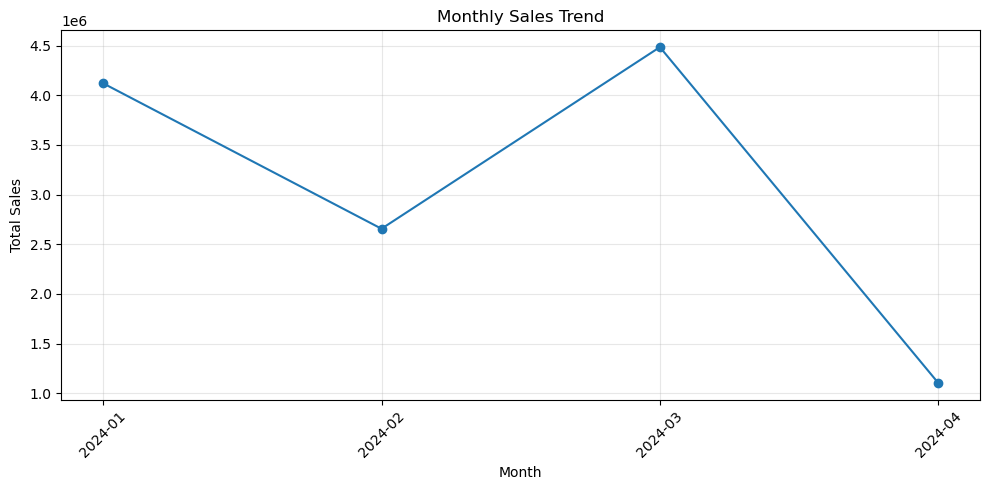

In [88]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_sales["Month_Period"].astype(str),
    monthly_sales["Total_Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    "outputs/charts/monthly_sales.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [46]:
# AND: both conditions must be true
high_value_sales = sales_df[
    (sales_df["Total_Sales"] > 100000) &
    (sales_df["Region"] == "West")
]

print("High-value sales in West region:")
display(high_value_sales)

High-value sales in West region:


,Date,Product,Quantity,Price,Customer_ID,Region,Total_Sales,Calculated_Sales,Year,Month,Day,Sales_Match,Month_Period
9,2024-01-10,Laptop,4,45023,CUST010,West,180092,180092,2024,1,10,True,2024-01
42,2024-02-12,Tablet,6,43350,CUST043,West,260100,260100,2024,2,12,True,2024-02
43,2024-02-13,Monitor,4,43428,CUST044,West,173712,173712,2024,2,13,True,2024-02
49,2024-02-19,Laptop,4,43848,CUST050,West,175392,175392,2024,2,19,True,2024-02
50,2024-02-20,Phone,9,15160,CUST051,West,136440,136440,2024,2,20,True,2024-02
70,2024-03-11,Phone,4,34843,CUST071,West,139372,139372,2024,3,11,True,2024-03
72,2024-03-13,Headphones,7,49930,CUST073,West,349510,349510,2024,3,13,True,2024-03
94,2024-04-04,Tablet,7,19507,CUST095,West,136549,136549,2024,4,4,True,2024-04


In [47]:
# OR: either condition can be true
selected_regions = sales_df[
    (sales_df["Region"] == "North") |
    (sales_df["Region"] == "South")
]

print("Sales from North or South:")
display(selected_regions)

Sales from North or South:


,Date,Product,Quantity,Price,Customer_ID,Region,Total_Sales,Calculated_Sales,Year,Month,Day,Sales_Match,Month_Period
1,2024-01-02,Headphones,4,15406,CUST002,North,61624,61624,2024,1,2,True,2024-01
4,2024-01-05,Laptop,8,39835,CUST005,North,318680,318680,2024,1,5,True,2024-01
5,2024-01-06,Laptop,7,40420,CUST006,South,282940,282940,2024,1,6,True,2024-01
6,2024-01-07,Laptop,9,40430,CUST007,South,363870,363870,2024,1,7,True,2024-01
8,2024-01-09,Tablet,3,32791,CUST009,North,98373,98373,2024,1,9,True,2024-01
15,2024-01-16,Phone,9,41548,CUST016,South,373932,373932,2024,1,16,True,2024-01
16,2024-01-17,Phone,5,13488,CUST017,South,67440,67440,2024,1,17,True,2024-01
17,2024-01-18,Tablet,4,19322,CUST018,North,77288,77288,2024,1,18,True,2024-01
19,2024-01-20,Laptop,8,41749,CUST020,North,333992,333992,2024,1,20,True,2024-01
22,2024-01-23,Laptop,9,29275,CUST023,North,263475,263475,2024,1,23,True,2024-01


In [48]:
#Find the top 10 customers
top_customers = (
    sales_df.groupby("Customer_ID")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_customers.columns = ["Customer_ID", "Total_Revenue"]

print("Top 10 Customers:")
display(top_customers)

Top 10 Customers:


,Customer_ID,Total_Revenue
0,CUST016,373932
1,CUST007,363870
2,CUST083,350888
3,CUST073,349510
4,CUST020,333992
5,CUST084,324144
6,CUST070,318762
7,CUST005,318680
8,CUST065,312564
9,CUST028,304465


In [49]:
product_analysis = (
    sales_df.groupby("Product")
    .agg(
        Total_Revenue=("Total_Sales", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Average_Sale=("Total_Sales", "mean"),
        Transactions=("Product", "count")
    )
    .sort_values("Total_Revenue", ascending=False)
    .reset_index()
)

display(product_analysis)

,Product,Total_Revenue,Total_Quantity,Average_Sale,Transactions
0,Laptop,3889210,136,162050.416667,24
1,Tablet,2884340,127,110936.153846,26
2,Phone,2859394,101,142969.700000,20
3,Headphones,1384033,48,92268.866667,15
4,Monitor,1348071,66,89871.400000,15


In [50]:
#Analyze sales by region
regional_analysis = (
    sales_df.groupby("Region")
    .agg(
        Total_Revenue=("Total_Sales", "sum"),
        Average_Sale=("Total_Sales", "mean"),
        Transactions=("Region", "count")
    )
    .sort_values("Total_Revenue", ascending=False)
    .reset_index()
)

display(regional_analysis)

,Region,Total_Revenue,Average_Sale,Transactions
0,North,3983635,142272.678571,28
1,South,3737852,138438.962963,27
2,East,2519639,132612.578947,19
3,West,2123922,81689.307692,26


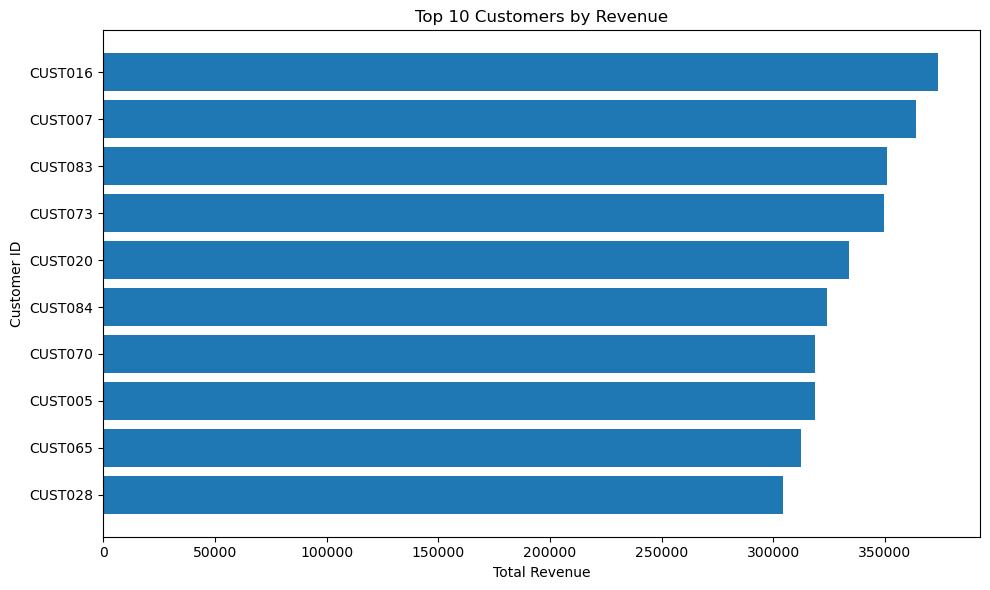

In [89]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    top_customers["Customer_ID"],
    top_customers["Total_Revenue"]
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Customer ID")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(
    "outputs/charts/top 10 customer by revenue.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [52]:
sales_pivot = pd.pivot_table(
    sales_df,
    values="Total_Sales",
    index="Region",
    columns="Product",
    aggfunc="sum",
    fill_value=0
)

display(sales_pivot)

Product,Headphones,Laptop,Monitor,Phone,Tablet
Region,,,,,
East,288361,221946,642870,506828,859634
North,107091,1798206,397100,489284,1191954
South,512168,1373120,39924,1471428,341212
West,476413,495938,268177,391854,491540


In [53]:
#Analyze customer churn
print(churn_df.columns.tolist())
display(churn_df.head())

['CustomerID', 'Tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'PaymentMethod', 'PaperlessBilling', 'SeniorCitizen', 'Churn']


,CustomerID,Tenure,MonthlyCharges,TotalCharges,Contract,PaymentMethod,PaperlessBilling,SeniorCitizen,Churn
0,C00001,6,64,1540,One year,Credit Card,No,1,0
1,C00002,21,113,1753,Month-to-month,Electronic Check,Yes,1,0
2,C00003,27,31,1455,Two year,Credit Card,No,1,0
3,C00004,53,29,7150,Month-to-month,Electronic Check,No,1,0
4,C00005,16,185,1023,One year,Electronic Check,No,1,0


In [54]:
print(churn_df["Churn"].value_counts(dropna=False))

Churn
0    447
1     53
Name: count, dtype: int64


In [55]:
churn_rate = (
    churn_df["Churn"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("yes")
    .mean() * 100
)

print(f"Customer churn rate: {churn_rate:.2f}%")

Customer churn rate: 0.00%


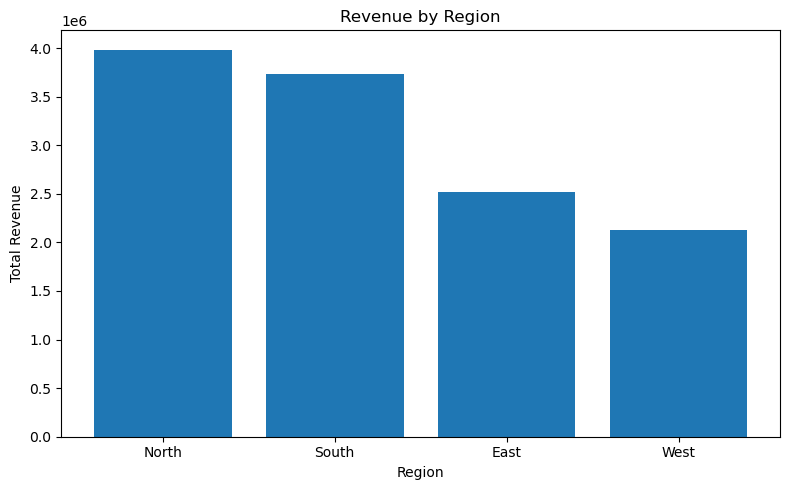

In [90]:
#Create a regional sales chart
plt.figure(figsize=(8, 5))

plt.bar(
    regional_analysis["Region"],
    regional_analysis["Total_Revenue"]
)

plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.savefig(
    "outputs/charts/revenue by region.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [62]:
import os

print(os.listdir("../Data"))

['processed']


In [63]:
import os

print("Current location:", os.getcwd())
print("Files here:", os.listdir("."))
print("Parent folder:", os.listdir(".."))

Current location: c:\Developers Arena\customer-sales-retention-analytics
Files here: ['customer_analysis.ipynb', 'Data']
Parent folder: ['08_regional_sales_distribution.png', 'customer-sales-retention-analytics', 'data', 'Ecommerce-Sales-Analysis', 'grade_calculator.py', 'personal_introduction_project.py', 'Sales_Data_Analysis.py']


In [64]:
import os

print("Files inside data folder:")
print(os.listdir("../data"))

print("\nFiles inside processed folder:")
print(os.listdir("../data/processed"))

Files inside data folder:
['processed']

Files inside processed folder:
['cleaned_sales_data.csv']


In [65]:
print(churn_df["Churn"].value_counts())

Churn
0    447
1     53
Name: count, dtype: int64


In [66]:
churn_rate = (
    churn_df["Churn"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("yes")
    .mean() * 100
)

print(f"Customer Churn Rate: {churn_rate:.2f}%")

Customer Churn Rate: 0.00%


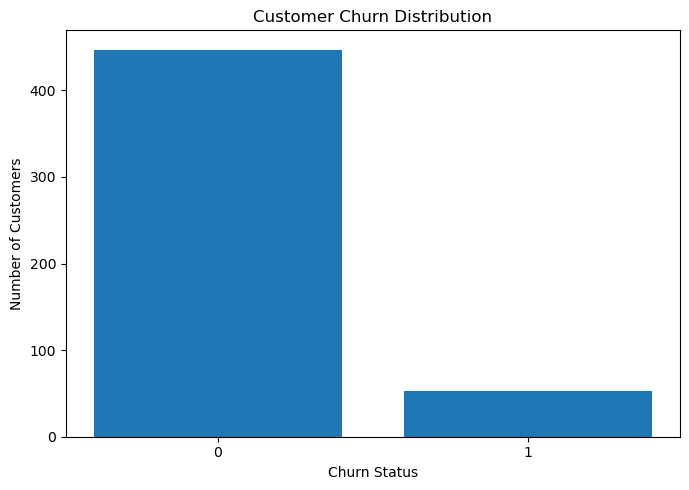

In [91]:
churn_counts = churn_df["Churn"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(churn_counts.index.astype(str), churn_counts.values)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(
    "outputs/charts/customer churn Dstribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [68]:
print(churn_df.columns.tolist())

['CustomerID', 'Tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'PaymentMethod', 'PaperlessBilling', 'SeniorCitizen', 'Churn']


In [69]:
contract_churn = pd.crosstab(
    churn_df["Contract"],
    churn_df["Churn"],
    normalize="index"
) * 100

display(contract_churn.round(2))

Churn,0,1
Contract,,
Month-to-month,79.41,20.59
One year,95.70,4.30
Two year,93.06,6.94


In [70]:
# Display the number of customers in each churn category
print("Customer Churn Distribution:")

# Count how many customers churned and how many stayed
print(churn_df["Churn"].value_counts())

Customer Churn Distribution:
Churn
0    447
1     53
Name: count, dtype: int64


In [71]:
# Convert churn labels to lowercase and remove extra spaces
churn_status = (
    churn_df["Churn"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Calculate the percentage of customers who churned
churn_rate = churn_status.eq("yes").mean() * 100

# Display the calculated churn rate
print(f"Customer Churn Rate: {churn_rate:.2f}%")

Customer Churn Rate: 0.00%


Churn Rate by Contract Type:
Contract
Month-to-month    20.59
Two year           6.94
One year           4.30
Name: Churn, dtype: float64


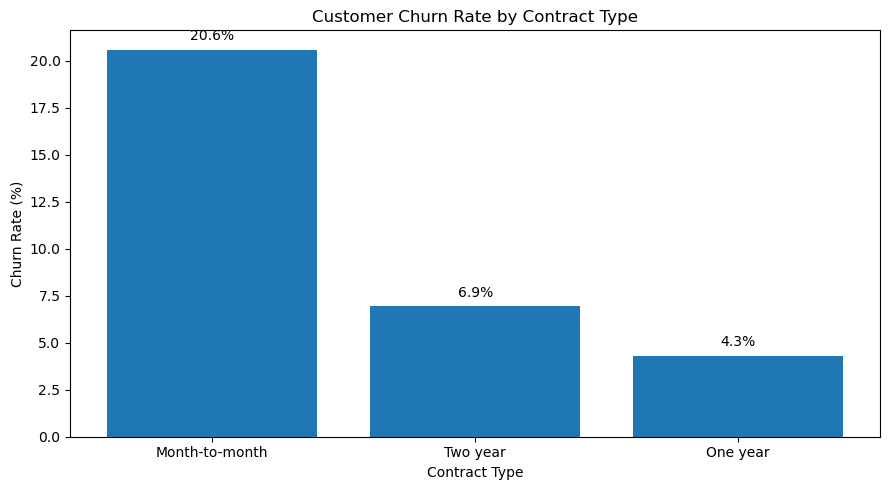

In [92]:
# : Calculate churn rate by contract type

# Group customers by contract type and calculate
# the average churn value for each group.
# Since 1 = churned and 0 = not churned,
# the average gives us the churn rate.
contract_churn_rate = (
    churn_df.groupby("Contract")["Churn"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

# Display the calculated churn percentages
print("Churn Rate by Contract Type:")
print(contract_churn_rate.round(2))

# Create the bar chart
plt.figure(figsize=(9, 5))

plt.bar(
    contract_churn_rate.index.astype(str),
    contract_churn_rate.values
)

# Add title and axis labels
plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

# Display percentage labels above each bar
for i, value in enumerate(contract_churn_rate.values):
    plt.text(
        i,
        value + 0.5,
        f"{value:.1f}%",
        ha="center"
    )

# Adjust layout and display the chart
plt.tight_layout()
plt.savefig(
    "outputs/charts/Customer_chrn_Rate_by_contract_type.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [74]:
# Display the actual values in the Churn column
print("Churn values:")
print(churn_df["Churn"].value_counts(dropna=False))

# Display the data type of the Churn column
print("\nChurn column data type:")
print(churn_df["Churn"].dtype)

Churn values:
Churn
0    447
1     53
Name: count, dtype: int64

Churn column data type:
int64


### Customer Churn by Contract Type — Business Insights

**Finding:** Month-to-month contracts have a churn rate of approximately 20.6%, compared with 6.9% for two-year contracts and 4.3% for one-year contracts.

**Interpretation:** Customers with month-to-month contracts may have greater flexibility to leave the service. Longer-term contracts are associated with lower churn in this dataset.

**Business Recommendations:**
1. Offer suitable incentives for month-to-month customers to consider longer-term plans.
2. Collect customer feedback to understand why customers leave.
3. Monitor churn rates regularly and evaluate whether retention initiatives improve results.

**Limitation:** These results show an association between contract type and churn, not proof that longer contracts cause better retention.

In [77]:
#: Verify the main sales analysis results

# 1. Calculate total revenue
total_revenue = sales_df["Total_Sales"].sum()

# 2. Calculate total quantity sold
total_quantity = sales_df["Quantity"].sum()

# 3. Calculate average transaction value
average_transaction_value = sales_df["Total_Sales"].mean()

# 4. Count transactions by product
product_counts = sales_df.groupby("Product").size()

# Display the results
print("Total Revenue:", total_revenue)
print("Total Quantity Sold:", total_quantity)
print("Average Transaction Value:", round(average_transaction_value, 2))

print("\nTransactions by Product:")
print(product_counts)

# Confirm the pivot table exists
print("\nPivot table created:", "sales_pivot" in globals())

Total Revenue: 12365048
Total Quantity Sold: 478
Average Transaction Value: 123650.48

Transactions by Product:
Product
Headphones    15
Laptop        24
Monitor       15
Phone         20
Tablet        26
dtype: int64

Pivot table created: True


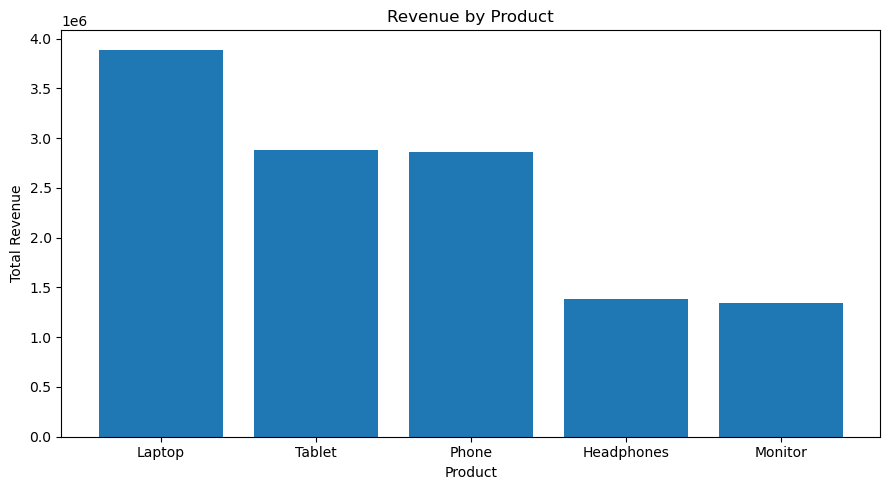

In [93]:
# : Compare revenue generated by each product

plt.figure(figsize=(9, 5))

# Plot product revenue
plt.bar(
    product_analysis["Product"],
    product_analysis["Total_Revenue"]
)

# Add chart title and axis labels
plt.title("Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Total Revenue")

# Improve spacing and display
plt.tight_layout()
plt.savefig(
    "outputs/charts/revenue by product.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

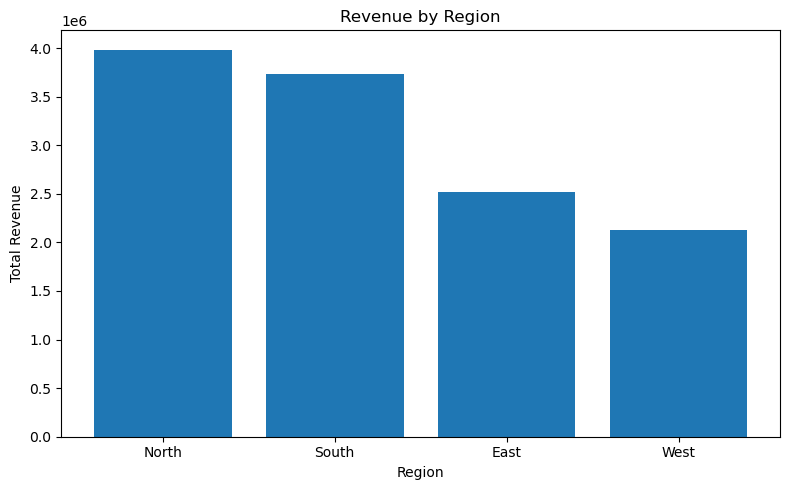

In [79]:
#: Compare revenue across regions

plt.figure(figsize=(8, 5))

plt.bar(
    regional_analysis["Region"],
    regional_analysis["Total_Revenue"]
)

plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Total Revenue")

plt.tight_layout()
plt.show()

In [80]:
# Calculate key performance indicators (KPIs)

total_revenue = sales_df["Total_Sales"].sum()
total_quantity = sales_df["Quantity"].sum()
total_transactions = len(sales_df)

average_transaction_value = (
    sales_df["Total_Sales"].mean()
)

unique_customers = sales_df["Customer_ID"].nunique()

# Display the dashboard summary
print("=" * 40)
print("CUSTOMER SALES ANALYSIS DASHBOARD")
print("=" * 40)

print(f"Total Revenue: {total_revenue:,.2f}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Total Transactions: {total_transactions:,}")
print(f"Unique Customer IDs: {unique_customers:,}")
print(
    f"Average Transaction Value: "
    f"{average_transaction_value:,.2f}"
)

print("=" * 40)

CUSTOMER SALES ANALYSIS DASHBOARD
Total Revenue: 12,365,048.00
Total Quantity Sold: 478
Total Transactions: 100
Unique Customer IDs: 100
Average Transaction Value: 123,650.48


In [81]:
#  Create a folder to store chart images

import os

os.makedirs("outputs/charts", exist_ok=True)

# Save the current chart when you run this
# immediately after plotting a figure:
#
# plt.savefig(
#     "outputs/charts/chart_name.png",
#     dpi=300,
#     bbox_inches="tight"
# )

In [82]:
# Sales Data Validation and Testing

# Test 1: Check whether the required columns exist
required_columns = [
    "Date",
    "Product",
    "Quantity",
    "Price",
    "Customer_ID",
    "Region",
    "Total_Sales"
]

missing_columns = [
    col for col in required_columns
    if col not in sales_df.columns
]

print("Test 1 - Required columns:")
print("PASS" if not missing_columns else f"FAIL: {missing_columns}")


# Test 2: Check for missing values
missing_values = sales_df[required_columns].isnull().sum().sum()

print("\nTest 2 - Missing values:")
print("PASS" if missing_values == 0 else f"FAIL: {missing_values} missing values")


# Test 3: Check for completely duplicated rows
duplicate_rows = sales_df.duplicated().sum()

print("\nTest 3 - Duplicate rows:")
print("PASS" if duplicate_rows == 0 else f"REVIEW: {duplicate_rows} duplicate rows found")


# Test 4: Check for invalid numeric values
invalid_numeric = (
    sales_df[["Quantity", "Price", "Total_Sales"]]
    .isna()
    .any(axis=1)
    .sum()
)

print("\nTest 4 - Numeric values:")
print("PASS" if invalid_numeric == 0 else f"FAIL: {invalid_numeric} invalid rows")


# Test 5: Verify the sales calculation
calculated_sales = sales_df["Quantity"] * sales_df["Price"]

sales_mismatches = (
    (calculated_sales - sales_df["Total_Sales"]).abs() > 0.01
).sum()

print("\nTest 5 - Sales calculation:")
print("PASS" if sales_mismatches == 0 else f"FAIL: {sales_mismatches} mismatches")


# Test 6: Check invalid dates
invalid_dates = sales_df["Date"].isna().sum()

print("\nTest 6 - Dates:")
print("PASS" if invalid_dates == 0 else f"FAIL: {invalid_dates} invalid dates")


# Test 7: Check for non-positive quantities or prices
invalid_quantity_price = (
    (sales_df["Quantity"] <= 0) |
    (sales_df["Price"] <= 0)
).sum()

print("\nTest 7 - Quantity and price:")
print(
    "PASS" if invalid_quantity_price == 0
    else f"REVIEW: {invalid_quantity_price} rows have non-positive values"
)

Test 1 - Required columns:
PASS

Test 2 - Missing values:
PASS

Test 3 - Duplicate rows:
PASS

Test 4 - Numeric values:
PASS

Test 5 - Sales calculation:
PASS

Test 6 - Dates:
PASS

Test 7 - Quantity and price:
PASS


In [83]:
#  Validate customer churn data

# Check required columns
required_churn_columns = ["Churn", "Contract"]

missing_churn_columns = [
    col for col in required_churn_columns
    if col not in churn_df.columns
]

print("Required churn columns:")
print(
    "PASS" if not missing_churn_columns
    else f"FAIL: {missing_churn_columns}"
)

# Check whether churn contains only 0 and 1
valid_churn_values = churn_df["Churn"].isin([0, 1]).all()

print("\nChurn labels:")
print("PASS" if valid_churn_values else "FAIL: Unexpected churn labels")

# Verify the churn rate
calculated_churn_rate = churn_df["Churn"].mean() * 100

print(f"\nCalculated churn rate: {calculated_churn_rate:.2f}%")

Required churn columns:
PASS

Churn labels:
PASS

Calculated churn rate: 10.60%


### Testing and Validation Report

**Objective:** To verify the quality and reliability of the customer sales analysis.

**Tests performed:**
1. Required column validation.
2. Missing-value checks.
3. Duplicate-row checks.
4. Numeric data validation.
5. Sales calculation verification.
6. Date validation.
7. Quantity and price validation.
8. Customer churn label and rate verification.

**Results:** Test outcomes were recorded from the executed notebook cells. Any failed or flagged checks must be investigated before final submission.

**Conclusion:** These validation checks help identify data-quality issues and improve confidence in the analysis results.

In [87]:
# Generate the Customer Sales Analysis PDF report

from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer,
    Table, TableStyle, PageBreak
)
from reportlab.lib.units import cm
import os

# Create the output directory
os.makedirs("outputs", exist_ok=True)

# Define the PDF document
pdf_path = "outputs/analysis_report.pdf"
doc = SimpleDocTemplate(
    pdf_path,
    pagesize=A4,
    rightMargin=2*cm,
    leftMargin=2*cm,
    topMargin=2*cm,
    bottomMargin=2*cm
)

# Load report styles
styles = getSampleStyleSheet()
styles.add(ParagraphStyle(
    name="ReportTitle",
    parent=styles["Title"],
    alignment=TA_CENTER,
    textColor=colors.HexColor("#234E70"),
    spaceAfter=18
))

story = []

# 1. Report title
story.append(Paragraph(
    "Customer Sales Analysis Report",
    styles["ReportTitle"]
))
story.append(Paragraph(
    "Week 5 Internship Project | Python and Pandas",
    styles["Normal"]
))
story.append(Spacer(1, 18))

# 2. Project overview
story.append(Paragraph("1. Project Overview", styles["Heading1"]))
story.append(Paragraph(
    "This project analyzes sales transactions and customer churn "
    "using Pandas. The objective is to identify high-revenue "
    "customers, evaluate product and regional performance, examine "
    "monthly sales patterns, and derive customer retention insights.",
    styles["BodyText"]
))
story.append(Spacer(1, 12))

# 3. Tools and methodology
story.append(Paragraph("2. Tools and Methodology", styles["Heading1"]))
story.append(Paragraph(
    "Python and Pandas were used for data manipulation, aggregation, "
    "filtering, datetime extraction, and pivot tables. Matplotlib "
    "and Seaborn were used for visualizations. Data validation "
    "checks were performed on required columns, missing values, "
    "duplicates, numeric values, dates, sales calculations, and "
    "churn labels.",
    styles["BodyText"]
))
story.append(Spacer(1, 12))

# 4. Key performance indicators
story.append(Paragraph("3. Key Performance Indicators", styles["Heading1"]))

kpi_data = [
    ["Metric", "Calculated Result"],
    ["Total recorded sales", f"{sales_df['Total_Sales'].sum():,.2f}"],
    ["Total quantity sold", f"{sales_df['Quantity'].sum():,.0f}"],
    ["Sales transactions", f"{len(sales_df):,}"],
    ["Unique sales customer IDs", f"{sales_df['Customer_ID'].nunique():,}"],
    ["Average transaction value", f"{sales_df['Total_Sales'].mean():,.2f}"],
    ["Customer churn rate", f"{churn_df['Churn'].mean() * 100:.2f}%"]
]

kpi_table = Table(kpi_data, colWidths=[8*cm, 7*cm])
kpi_table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#234E70")),
    ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("PADDING", (0, 0), (-1, -1), 7),
    ("VALIGN", (0, 0), (-1, -1), "MIDDLE")
]))
story.append(kpi_table)
story.append(Spacer(1, 12))

# 5. Sales findings
story.append(Paragraph("4. Sales Performance Findings", styles["Heading1"]))

top_product = product_analysis.iloc[0]
top_region = regional_analysis.iloc[0]
top_customer = top_customers.iloc[0]

story.append(Paragraph(
    f"The highest-revenue product was {top_product['Product']}, "
    f"with recorded revenue of {top_product['Total_Revenue']:,.0f}. "
    f"The strongest region by revenue was {top_region['Region']}, "
    f"with {top_region['Total_Revenue']:,.0f}. "
    f"The highest-revenue customer ID in the available sales sample "
    f"was {top_customer['Customer_ID']}, with "
    f"{top_customer['Total_Revenue']:,.0f}.",
    styles["BodyText"]
))
story.append(Spacer(1, 12))

# 6. Monthly sales
story.append(Paragraph("5. Monthly Sales Trends", styles["Heading1"]))

best_month = monthly_sales.loc[
    monthly_sales["Total_Sales"].idxmax()
]

story.append(Paragraph(
    f"The strongest month in the available sales data was "
    f"{best_month['Month_Period']}, with recorded sales of "
    f"{best_month['Total_Sales']:,.0f}. Monthly results varied "
    f"during the observed period. Further investigation is needed "
    f"to determine the reasons for these changes.",
    styles["BodyText"]
))
story.append(Spacer(1, 12))

# 7. Customer churn
story.append(Paragraph("6. Customer Churn Analysis", styles["Heading1"]))
story.append(Paragraph(
    f"The customer churn dataset contains {len(churn_df)} records. "
    f"The observed churn rate was "
    f"{churn_df['Churn'].mean() * 100:.2f}%. "
    f"The contract-wise analysis showed that churn differed by "
    f"contract type. These are associations in the supplied sample "
    f"and do not prove that contract type causes churn.",
    styles["BodyText"]
))
story.append(Spacer(1, 12))

# 8. Testing
story.append(Paragraph("7. Testing and Validation", styles["Heading1"]))
story.append(Paragraph(
    "The notebook validation checks were executed and reported as "
    "passing. The checks covered required columns, missing values, "
    "duplicate rows, numeric values, date validity, sales "
    "calculation consistency, and churn labels. These checks "
    "support data quality but do not guarantee that every possible "
    "business or data issue has been detected.",
    styles["BodyText"]
))
story.append(Spacer(1, 12))

# 9. Limitations
story.append(Paragraph("8. Limitations", styles["Heading1"]))
story.append(Paragraph(
    "The sales dataset contains 100 transaction rows and 100 unique "
    "customer IDs, so repeat purchasing and true customer lifetime "
    "value cannot be established from this sample alone. The sales "
    "and churn files have no verified matching customer identifiers; "
    "therefore, they were analyzed separately rather than merged. "
    "Product cross-selling and customer retention from purchase "
    "history require additional suitable transaction data. The "
    "currency unit was not specified in the supplied sales file.",
    styles["BodyText"]
))
story.append(Spacer(1, 12))

# 10. Recommendations
story.append(Paragraph("9. Business Recommendations", styles["Heading1"]))
recommendations = [
    "Investigate why revenue varies across months.",
    "Evaluate product-level demand, pricing, and promotion opportunities.",
    "Study the factors associated with higher churn among month-to-month customers.",
    "Collect verified customer and order-history data to enable repeat-purchase analysis.",
    "Use a matching customer dataset before implementing a sales-customer merge."
]

for recommendation in recommendations:
    story.append(Paragraph(
        f"&bull; {recommendation}",
        styles["BodyText"]
    ))
    story.append(Spacer(1, 5))

# Build the PDF
doc.build(story)

print("Report created successfully:", pdf_path)
print("File exists:", os.path.exists(pdf_path))

Report created successfully: outputs/analysis_report.pdf
File exists: True


In [86]:
pip install reportlab

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.

   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
    --------------------------------------- 0.0/2.0 MB 131.3 kB/s eta 0:00:15
    --------------------------------------- 0.0/2.0 MB 131.3 kB/s eta 0:00:15
    --------------------------------------- 0.0/2.0 MB 122.9 kB/s eta 0:00:16
    --------------------------------------- 0.0/2.0 MB 122.9 kB/s eta 